In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score

In [4]:
df = pd.read_csv("C:/Users/AMOL/Downloads/Mall_Customers.csv")
print (df.head())

   CustomerID  Gender  Age  Annual Income (k$)  Spending Score (1-100)
0           1    Male   19                  15                      39
1           2    Male   21                  15                      81
2           3  Female   20                  16                       6
3           4  Female   23                  16                      77
4           5  Female   31                  17                      40


In [5]:
print("\nDataset Shape:")
print(df.shape)


Dataset Shape:
(200, 5)


In [6]:
print("nMissing values:")
print( df.isnull().sum() )

nMissing values:
CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64


In [7]:
print("\nDataset info:")
print(df.info())


Dataset info:
<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   CustomerID              200 non-null    int64
 1   Gender                  200 non-null    str  
 2   Age                     200 non-null    int64
 3   Annual Income (k$)      200 non-null    int64
 4   Spending Score (1-100)  200 non-null    int64
dtypes: int64(4), str(1)
memory usage: 8.9 KB
None


In [8]:
df.columns = ["CustomerID", "Gender", "Age", "Annual Income", "Spending Score"]

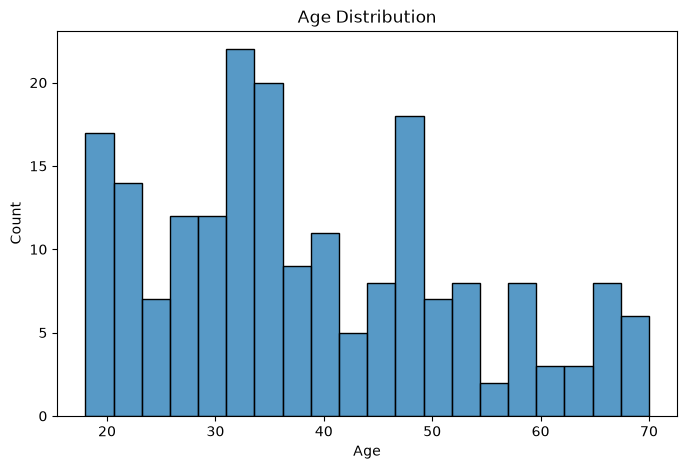

In [9]:
plt.figure(figsize = (8,5))
sns.histplot(df['Age'], bins = 20)
plt.title("Age Distribution")
plt.show()

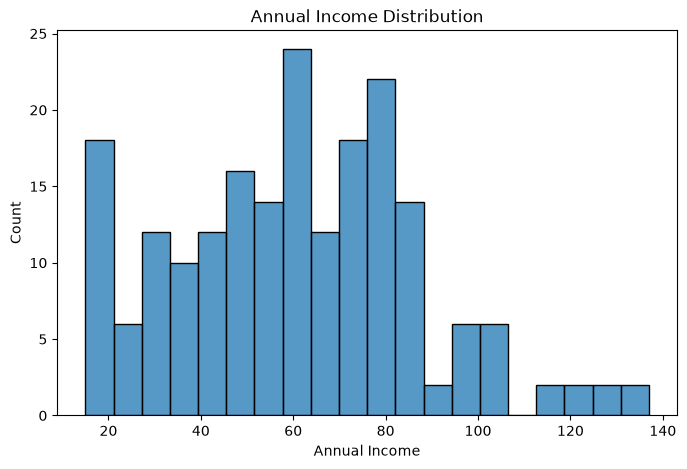

In [10]:
plt.figure(figsize = (8,5))
sns.histplot(df['Annual Income'], bins = 20)
plt.title("Annual Income Distribution")
plt.show()

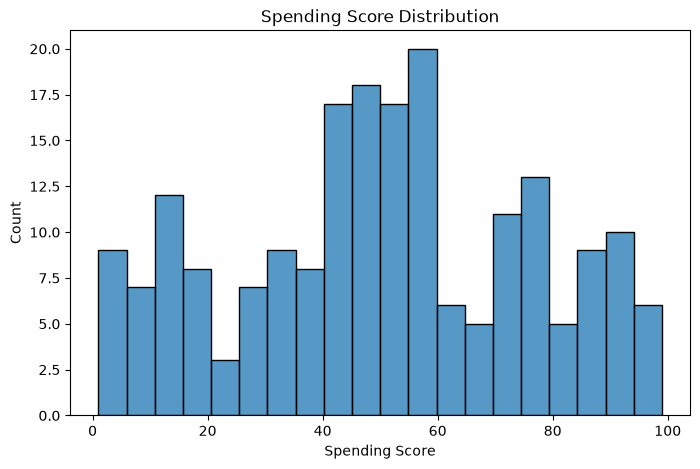

In [11]:
plt.figure(figsize = (8,5))
sns.histplot(df['Spending Score'], bins = 20)
plt.title("Spending Score Distribution")
plt.show()

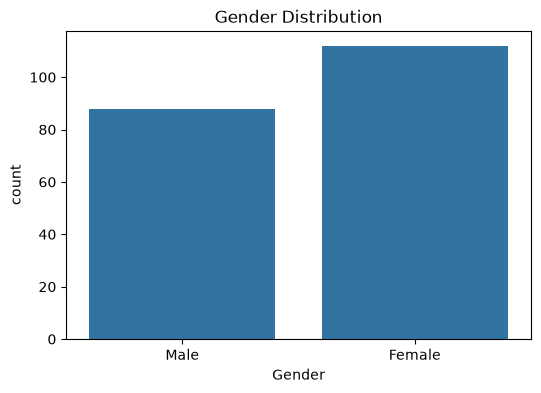

In [12]:
plt.figure(figsize = (6,4))
sns.countplot(x = 'Gender', data = df)
plt.title("Gender Distribution")
plt.show()

In [13]:
df['Gender'] = df["Gender"].map({'Male':0, 'Female':1})

In [14]:
x = df [ ['Gender', 'Age', 'Annual Income', 'Spending Score'] ]

In [15]:
scaler = StandardScaler()
x_scaled = scaler.fit_transform(x)

C:\ProgramData\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\ProgramData\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\ProgramData\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\ProgramData\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Window

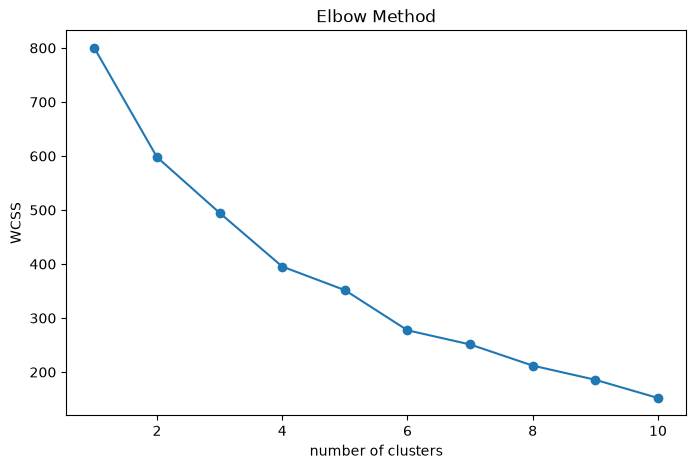

In [16]:
wcss = []
for i in range(1,11):
    kmeans = KMeans(n_clusters=i, init='k-means++', random_state=42)
    kmeans.fit(x_scaled)
    wcss.append(kmeans.inertia_)

plt.figure(figsize =(8,5))
plt.plot(range(1,11), wcss, marker= 'o')
plt.title("Elbow Method")
plt.xlabel("number of clusters")
plt.ylabel("WCSS")
plt.show()

In [17]:
kmeans = KMeans(n_clusters = 5, init = 'k-means++', random_state=42)
clusters = kmeans.fit_predict(x_scaled)
df['Cluster'] = clusters

C:\ProgramData\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


In [18]:
score = silhouette_score(x_scaled, clusters)
print("\nSilhouette score:" , score)


Silhouette score: 0.27191023466188324


In [19]:
pca = PCA(n_components = 2)
x_pca = pca.fit_transform(x_scaled)

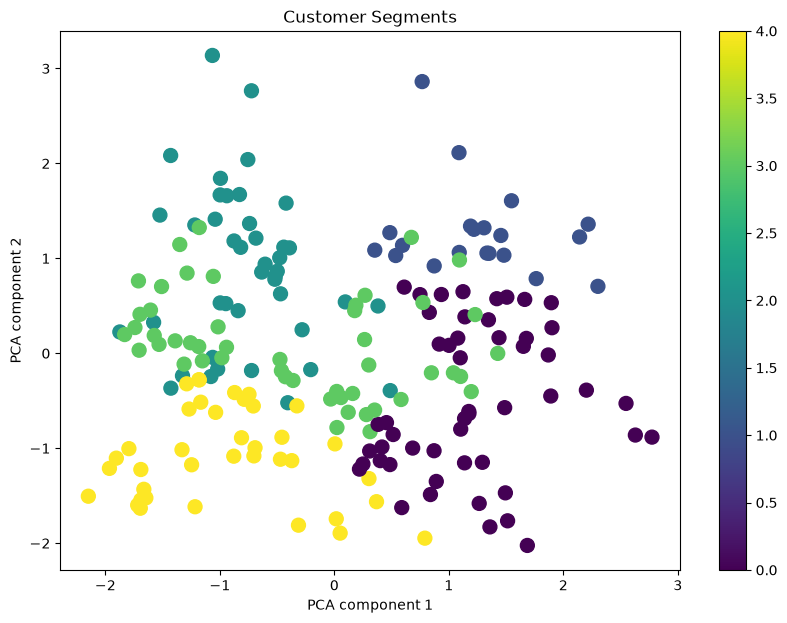

In [20]:
plt.figure(figsize=(10,7))
scatter = plt.scatter(x_pca[:,0], x_pca[:,1], c = df['Cluster'], cmap = 'viridis',  s=100)
plt.title("Customer Segments")
plt.xlabel("PCA component 1")
plt.ylabel("PCA component 2")
plt.colorbar(scatter)
plt.show()

In [21]:
cluster_summary = df.groupby('Cluster').mean()
print("\nCluster summary:")
print(cluster_summary)


Cluster summary:
         CustomerID    Gender        Age  Annual Income  Spending Score
Cluster                                                                
0         65.333333  0.490196  56.470588      46.098039       39.313725
1        159.500000  0.000000  39.500000      85.150000       14.050000
2        100.809524  0.000000  28.690476      60.904762       70.238095
3        151.510204  1.000000  37.897959      82.122449       54.448980
4         50.526316  1.000000  27.315789      38.842105       56.210526


In [22]:
for cluster in sorted(df['Cluster'].unique()):
    print(f"\n========Cluster{cluster}====")
    cluster_data = df[df['Cluster'] == cluster]
    print ("Average Age:", round (cluster_data['Age'].mean(),2))
    print ("Average Income:", round (cluster_data['Annual Income'].mean(),2))
    print ("Spending Score:", round (cluster_data['Spending Score'].mean(),2))
    income = cluster_data['Annual Income'].mean()
    spending = cluster_data['Spending Score'].mean()
    if income > 70 and spending > 70 :
        print("Insight: Premium Customers")
        print("Action: VIP offers and loyalty programs")
    elif income > 70 and spending < 40 :
        print("Insight: Rich but low spenders")
        print("Action: Personalized promotions")
    elif income < 40 and spending < 60 :
        print("Insight: Budget shoppers with high engagement")
        print("Action: Discount campaigns")
    else:
        print("Insight: Average customers")
        print("Action: General marketing")

df.to_csv("customer_segments_output.csv", index = False)
print("\nsegmented dataset saved successfully!")
        
        


========Cluster0====
Average Age: 56.47
Average Income: 46.1
Spending Score: 39.31
Insight: Average customers
Action: General marketing

========Cluster1====
Average Age: 39.5
Average Income: 85.15
Spending Score: 14.05
Insight: Rich but low spenders
Action: Personalized promotions

========Cluster2====
Average Age: 28.69
Average Income: 60.9
Spending Score: 70.24
Insight: Average customers
Action: General marketing

========Cluster3====
Average Age: 37.9
Average Income: 82.12
Spending Score: 54.45
Insight: Average customers
Action: General marketing

========Cluster4====
Average Age: 27.32
Average Income: 38.84
Spending Score: 56.21
Insight: Budget shoppers with high engagement
Action: Discount campaigns

segmented dataset saved successfully!


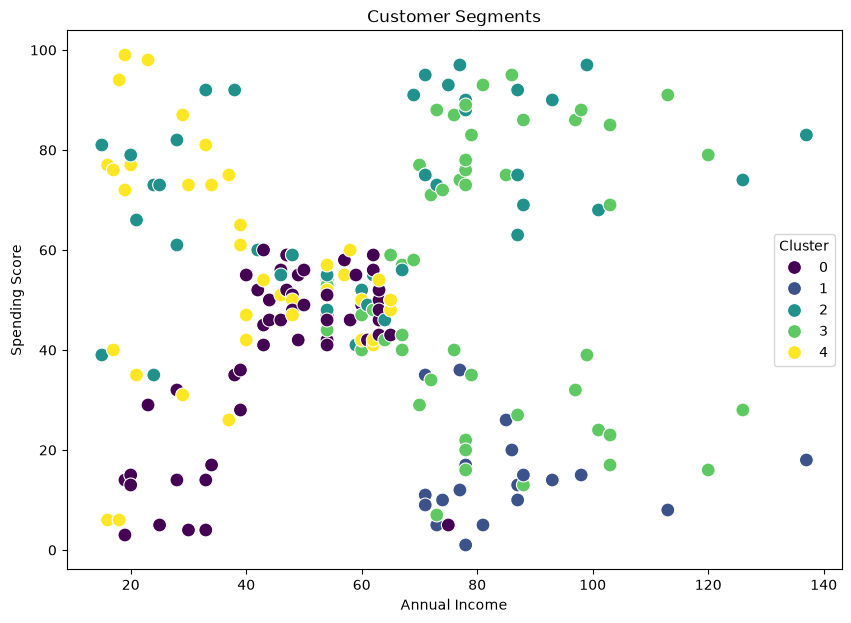

In [23]:
plt.figure(figsize= (10,7))

sns.scatterplot(
    x='Annual Income',
    y='Spending Score',
    hue='Cluster',
    palette='viridis',
    data=df,
    s=100,
)

plt.title("Customer Segments")
plt.xlabel("Annual Income")
plt.ylabel("Spending Score")

plt.show()

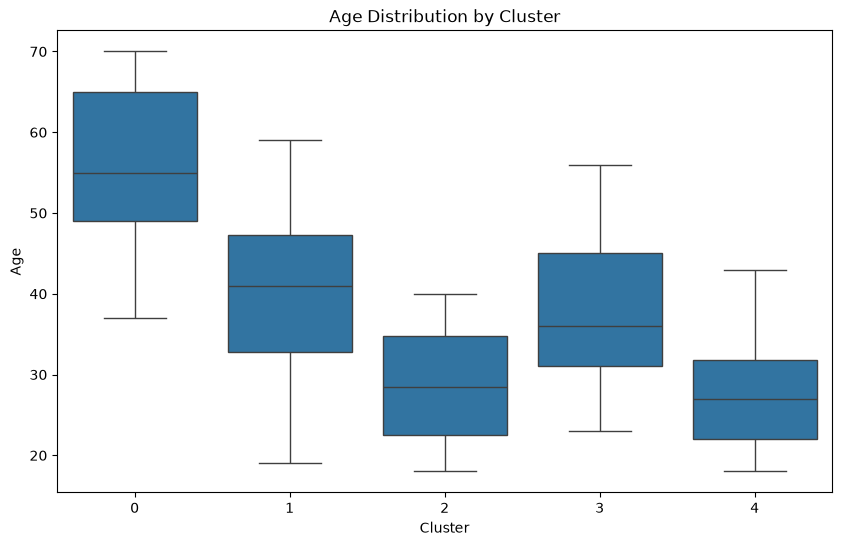

In [25]:
plt.figure(figsize=(10,6))

sns.boxplot(
    x='Cluster',
    y='Age',
    data=df
)

plt.title("Age Distribution by Cluster")
plt.show()

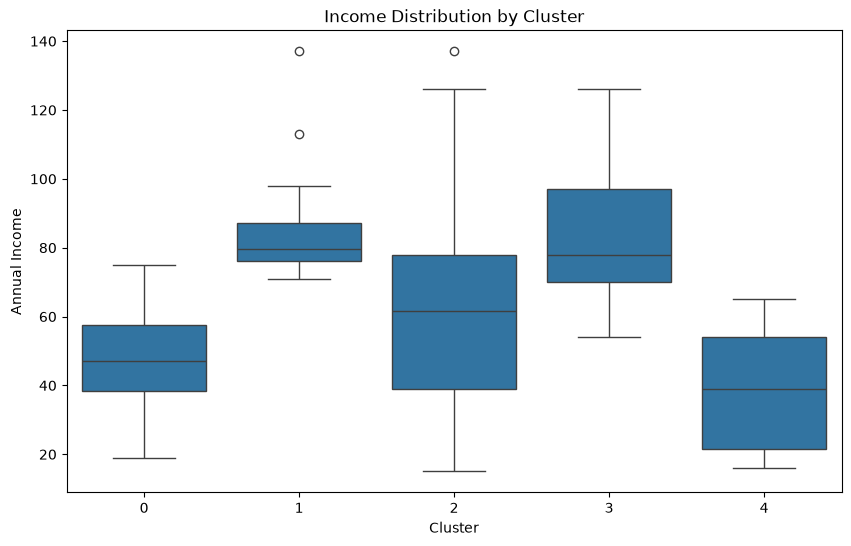

In [26]:
plt.figure(figsize=(10,6))

sns.boxplot(
    x='Cluster',
    y='Annual Income',
    data=df
)

plt.title("Income Distribution by Cluster")
plt.show()

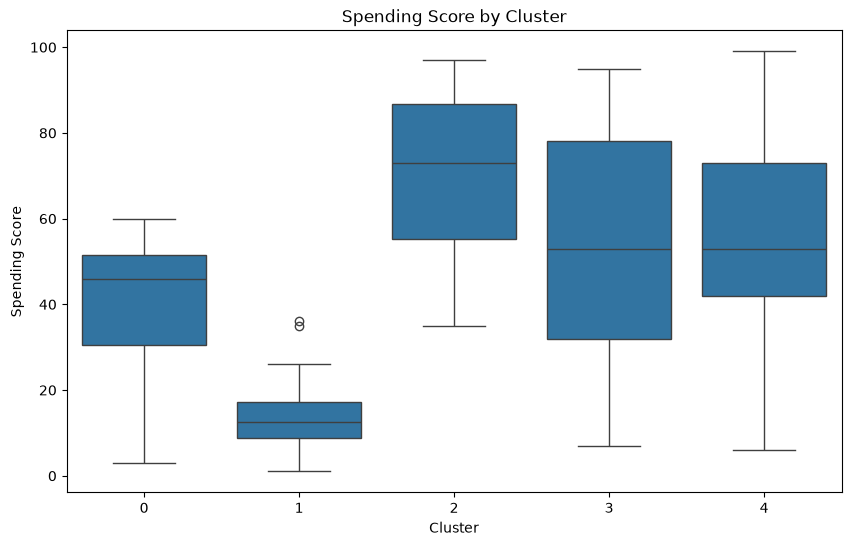

In [27]:
plt.figure(figsize=(10,6))

sns.boxplot(
    x='Cluster',
    y='Spending Score',
    data=df
)

plt.title("Spending Score by Cluster")
plt.show()

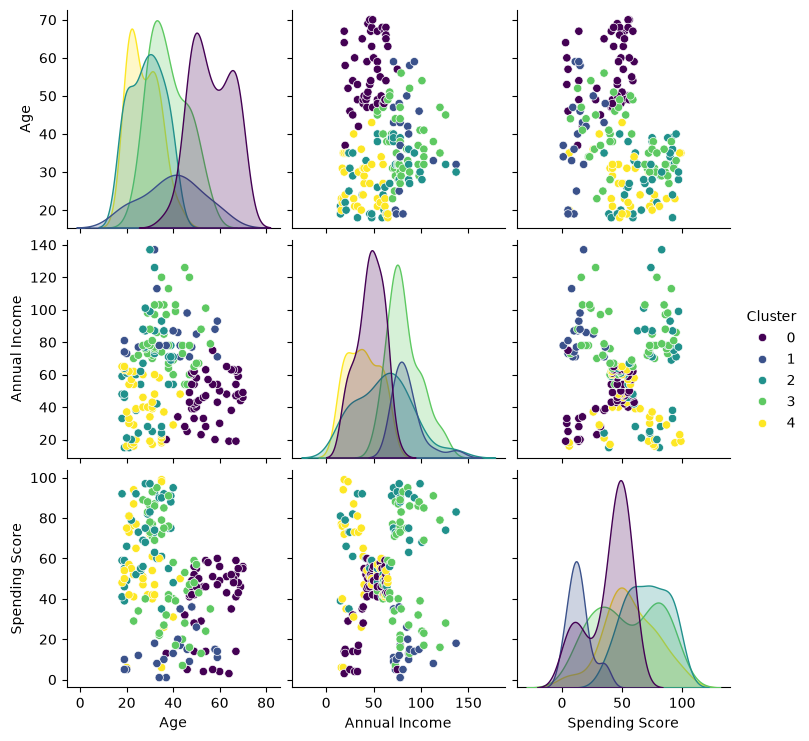

In [31]:
sns.pairplot(
    df,
    vars=['Age', 'Annual Income', 'Spending Score'],
    hue='Cluster',
    palette='viridis'
)

plt.show()

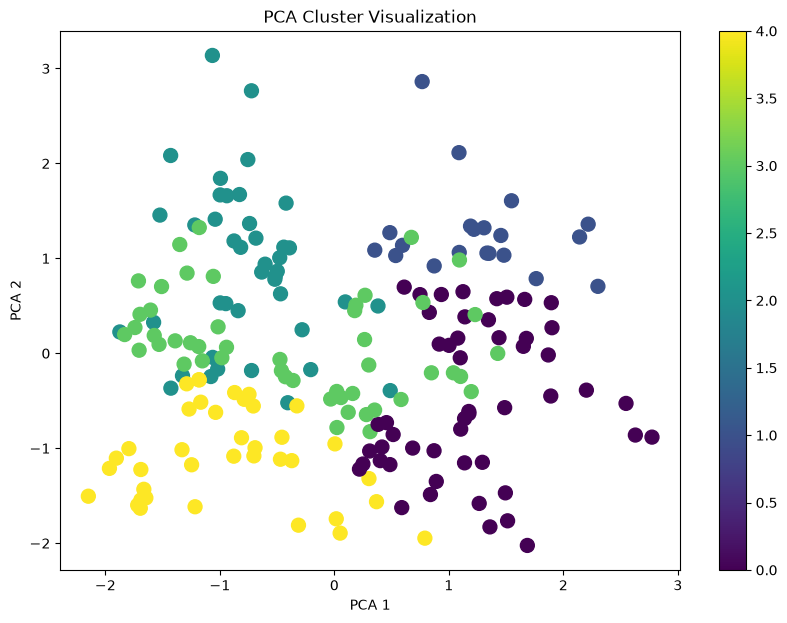

In [32]:
plt.figure(figsize=(10,7))

plt.scatter(
    x_pca[:,0],
    x_pca[:,1],
    c=df['Cluster'],
    cmap='viridis',
    s=100
)

plt.title("PCA Cluster Visualization")

plt.xlabel("PCA 1")
plt.ylabel("PCA 2")

plt.colorbar()

plt.show()

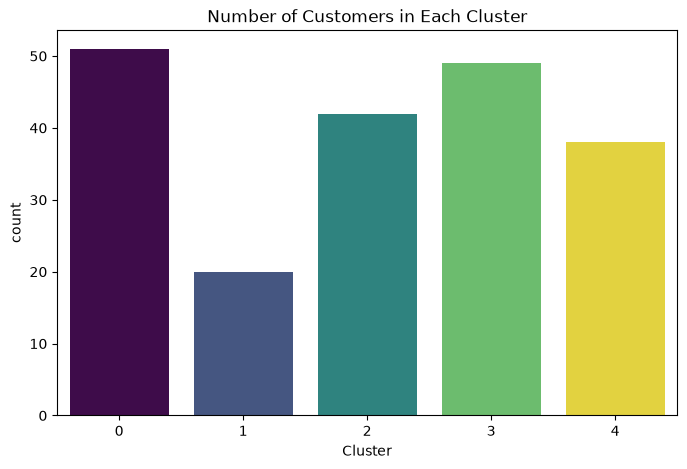

In [34]:
plt.figure(figsize=(8,5))

sns.countplot(
    x='Cluster',
    data=df,
    hue='Cluster',
    palette='viridis',
    legend=False
)

plt.title("Number of Customers in Each Cluster")

plt.show()

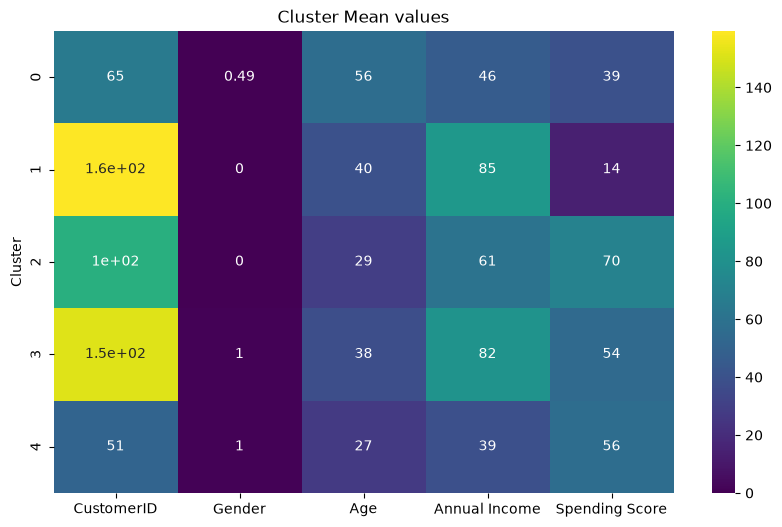

In [35]:
cluster_means = df.groupby('Cluster').mean()

plt.figure(figsize=(10,6))

sns.heatmap(
    cluster_means,
    annot=True,
    cmap='viridis'
)

plt.title('Cluster Mean values')

plt.show()